# Illustrations

Illustrative figures for the preprint, drawn from orbits integrated with Relatipy.

Figure format (Astronomy & Astrophysics), at the final printed size:

* width 88 mm (one column) or 180 mm (two columns, multi-panel only); schematics up to 1.2 times the width in height; no rescaling in LaTeX (`width=\hsize`)
* text 9 pt (symbols, panel labels) and 7.5 pt (annotations), never below 6 pt; Times-like serif (STIX)
* lines of at least 0.4 pt, markers of 2.5–4 pt
* all text in English
* black and white: line style and grey level tell the elements apart

Units $G=c=M=1$.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.path as mpath
from matplotlib.font_manager import FontProperties
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, PathPatch
from matplotlib.text import Text
from matplotlib.textpath import TextPath
import astropy.units as u
import astropy.constants as const
import relatipy as rp

plt.rcParams.update({
    "figure.figsize": (3.46, 2.6), "savefig.dpi": 300, "savefig.bbox": "tight", "savefig.pad_inches": 0.02,
    "font.family": "serif", "font.serif": ["Times New Roman", "Times", "Nimbus Roman", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix", "font.size": 9, "axes.labelsize": 9, "axes.titlesize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 7.5, "legend.frameon": False,
    "axes.linewidth": 0.6, "xtick.direction": "in", "ytick.direction": "in",
    "xtick.top": True, "ytick.right": True, "xtick.minor.visible": True, "ytick.minor.visible": True,
    "xtick.major.size": 3.5, "ytick.major.size": 3.5, "xtick.minor.size": 2, "ytick.minor.size": 2,
    "xtick.major.width": 0.6, "ytick.major.width": 0.6, "xtick.minor.width": 0.4, "ytick.minor.width": 0.4,
    "lines.linewidth": 1.0, "lines.markersize": 3, "errorbar.capsize": 1.5,
    "pdf.fonttype": 42,    # TrueType fonts embedded in the pdf
})

Shared helpers:

* `COLUMN`, `TWO_COLUMNS`: A&A figure widths [mm]; `MM` converts mm to inches
* `aanda_check`: checks a finished figure against the A&A rules (width, height, smallest text, thinnest line) and returns its size, font sizes and line widths
* `save_paper_figure`: saves pdf and png at the exact figure size into the preprint folder `figures/<section>/` (skipped if that folder is not next to this repository)

In [2]:
MM = 1 / 25.4                        # inches per mm
COLUMN, TWO_COLUMNS = 88.0, 180.0    # A&A widths [mm]
PAPER_FIGURES = Path("../../../thesis/preprint/figures")    # thesis repo next to relatipy; skipped if absent


def aanda_check(fig, max_height):
    """Assert the A&A size rules on a finished figure; size [mm], font sizes [pt] and line widths [pt]."""
    width, height = fig.get_figwidth() / MM, fig.get_figheight() / MM
    fonts = sorted({text.get_fontsize() for text in fig.findobj(Text) if text.get_visible() and text.get_text()})
    lines = sorted({
        artist.get_linewidth()
        for artist in fig.findobj(lambda artist: isinstance(artist, (Line2D, Patch)))
        if artist.get_visible() and artist.get_linewidth() > 0
    })
    assert round(width, 1) in (COLUMN, TWO_COLUMNS), f"width {width:.1f} mm"
    assert height <= max_height + 0.05, f"height {height:.1f} mm"
    assert not fonts or fonts[0] >= 6, f"text of {fonts[0]} pt"    # text drawn as paths is not seen
    assert lines[0] >= 0.4, f"line of {lines[0]} pt"
    return dict(
        width_mm=round(width, 1),
        height_mm=round(height, 1),
        fonts_pt=fonts,
        lines_pt=lines,
    )


def save_paper_figure(fig, section, name):
    """Save pdf + png at the exact figure size to the preprint figures folder of a section, when reachable."""
    if PAPER_FIGURES.is_dir():
        folder = PAPER_FIGURES / section
        folder.mkdir(exist_ok=True)
        with plt.rc_context({"savefig.bbox": "standard"}):    # a tight box would change the printed width
            fig.savefig(folder / f"{name}.pdf")
            fig.savefig(folder / f"{name}.png")

## 1. Lense-Thirring nodal precession

Bound orbit around a Kerr black hole with $\chi=1$, spin along $z$, started at apocentre ($f=180^\circ$) from Keplerian elements measured from the equatorial plane:

* semi-major axis $a=31.25M$ (semi-latus rectum $p=20M$), eccentricity $e=0.6$
* inclination $i=40^\circ$, argument of pericentre $\omega=45^\circ$, node $\Omega=0$
* DOP853, `rtol=1e-12`, `atol=1e-14`, five Keplerian periods with 3000 samples per period

How the elements are read:

* positions in the spin frame from the sky offsets seen by two observers, as in `01-Theoretical-Validations.ipynb` (Lense-Thirring section): `spin_frame_positions`
* velocities from centred differences of the positions (`np.gradient`)
* ascending nodes: crossings of $z=0$ upwards, with the state interpolated linearly to $z=0$
* at each node, the Newtonian osculating Kepler elements ($GM=1$) of that position and velocity: the ellipse the star would follow if gravity turned Newtonian at that instant. The field is strong ($r_p\approx 12M$), so near pericentre this ellipse departs from the path

In [3]:
MASS = 4.3e6 * u.Msun       # only sets the physical units; results in M
DISTANCE = 8.28 * u.kpc
bh0 = rp.Kerr(mass=MASS, spin=0.0)    # Keplerian initial state
LENGTH = bh0.r_g.to(u.au)                       # M [au]
TIME = (bh0.r_g / const.c).to(u.s)              # M [s]
SKY = (bh0.r_g / DISTANCE).to_value(u.arcsec, u.dimensionless_angles())    # arcsec per M
CYCLE = np.array([[0., 0., 1.], [1., 0., 0.], [0., 1., 0.]])    # second observer: its Dec offset is z
SOLVER = dict(method="dop853", rtol=1e-12, atol=1e-14, max_steps=10**8)


def initial_state(a, e, inc, omega, f=np.pi):
    """Cartesian (x [au], v [au/s]) in the spin frame from Keplerian elements; apocentre by default."""
    orbit = bh0.orbit(a=a * LENGTH, e=e, inc=inc * u.rad, Omega=0 * u.rad, omega=omega * u.rad, f=f * u.rad)
    return (
        np.array([q.to_value(u.au) for q in (orbit.x, orbit.y, orbit.z)]),
        np.array([q.to_value(u.au / u.s) for q in (orbit.vx, orbit.vy, orbit.vz)]),
    )


def spin_frame_positions(state, t, chi):
    """(x, y, z) [M] in the spin frame at coordinate times t [M], from the sky offsets seen by two observers."""
    position, velocity = state
    sky = []
    for rotation in (np.eye(3), CYCLE):
        x, v = rotation @ position, rotation @ velocity
        kerr = dict(mass=MASS, spin=chi, vec=tuple(rotation @ (0, 0, 1)))
        orbit = dict(
            x=x[0] * u.au, y=x[1] * u.au, z=x[2] * u.au,
            vx=v[0] * u.au / u.s, vy=v[1] * u.au / u.s, vz=v[2] * u.au / u.s,
        )
        alpha, delta, _ = rp.KerrMcmcModel().get_ra_dec_vr(
            kerr=kerr, orbit=orbit, sol=dict(t_eval=t * TIME, **SOLVER), distance=DISTANCE)
        sky.append((delta / SKY, alpha / SKY))
    (x, y), (z, x_again) = sky
    mismatch = np.abs(x_again - x).max() / np.abs(x).max()
    assert mismatch < 1e-4, f"the two observers disagree: {mismatch:.1e}"
    return np.stack([x, y, z], axis=1)


def osculating(x, v):
    """Newtonian osculating elements (GM = 1) of position x and velocity v; angles [rad]."""
    r = np.linalg.norm(x)
    h = np.cross(x, v)
    evec = np.cross(v, h) - x / r
    node = np.array([np.cos(np.arctan2(h[0], -h[1])), np.sin(np.arctan2(h[0], -h[1])), 0])
    q = np.cross(h / np.linalg.norm(h), node)
    return dict(
        a=1 / (2 / r - v @ v),
        e=np.linalg.norm(evec),
        inc=np.arccos(h[2] / np.linalg.norm(h)),
        Omega=np.arctan2(h[0], -h[1]),
        omega=np.arctan2(evec @ q, evec @ node),
    )


LT = dict(chi=1.0, p=20.0, e=0.6, inc=np.radians(40), omega=np.radians(45), n_periods=5)
a0 = LT["p"] / (1 - LT["e"]**2)
t = np.linspace(0, LT["n_periods"] * 2 * np.pi * a0**1.5, 3000 * LT["n_periods"] + 1)
x = spin_frame_positions(initial_state(a0, LT["e"], LT["inc"], LT["omega"]), t, LT["chi"])
v = np.gradient(x, t, axis=0)

cross = np.where((x[:-1, 2] < 0) & (x[1:, 2] >= 0))[0]
w = -x[cross, 2] / (x[cross + 1, 2] - x[cross, 2])
nodes = [osculating((1 - s) * x[i] + s * x[i + 1], (1 - s) * v[i] + s * v[i + 1]) for i, s in zip(cross, w)]
el = {key: np.array([node[key] for node in nodes]) for key in nodes[0]}
snap = cross + 1    # first sample above the plane at each node

pd.DataFrame(dict(
    t_M=t[cross] + w * (t[1] - t[0]),
    a_M=el["a"],
    e=el["e"],
    i_deg=np.degrees(el["inc"]),
    Omega_deg=np.degrees(np.unwrap(el["Omega"])),
    dOmega_deg=np.r_[np.nan, np.diff(np.degrees(np.unwrap(el["Omega"])))],
    omega_deg=np.degrees(el["omega"]),
), index=pd.Index(range(len(cross)), name="node"))

,t_M,a_M,e,i_deg,Omega_deg,dOmega_deg,omega_deg
node,,,,,,,
0,536.941279,21.522909,0.477718,38.943188,2.575061,NaN,63.340205
1,1637.935944,26.719243,0.563930,39.398798,11.089241,8.514180,104.795129
2,2618.366298,30.723055,0.600119,39.766768,20.164519,9.075279,147.365666
3,3339.900131,31.165442,0.600253,39.834459,29.542301,9.377782,-165.041697
4,4220.268403,28.700043,0.585959,39.562604,38.777827,9.235526,-120.356129
5,5294.216678,23.262732,0.511511,39.108741,47.514726,8.736898,-79.368678


Figure: the first four ascending nodes, $t_0$ to $t_3$ (three orbits).

* solid black: integrated path from $t_0$ to $t_3$
* dashed: osculating ellipse at each node; grey from light ($t_0$) to black ($t_3$)
* dots: ascending nodes, same grey as their ellipse
* (a) oblique view from $30^\circ$ above the equatorial plane: spin $\mathbf J$ and orbital angular momentum $\mathbf L$ at each node, on a dotted cone around $\mathbf J$
* (b) view from the spin axis: dotted lines of nodes; the arrow marks the advance of $\Omega$
* both panels share the azimuth of the view: the nodes face the viewer
* drawing units: apocentre at 48; same scale in both panels

In [4]:
SNAPS = [0, 1, 2, 3]
GREYS = ["0.75", "0.58", "0.38", "0.0"]    # t0 (light) to t3 (black)
ELEV = np.radians(30)                      # panel (a) view elevation
R_PLANE, L_LEN, J_LEN = 55.0, 40.0, 58.0   # drawing units
ANNOTATION = 7.5                           # [pt]

SCALE = 48 / np.linalg.norm(x, axis=1).max()
xs = x * SCALE
els = dict(el, a=el["a"] * SCALE)
Omega = np.unwrap(els["Omega"])
ROT = np.radians(-90) - Omega[[SNAPS[0], SNAPS[-1]]].mean()    # screen azimuth: nodes toward the viewer


def kepler(k, f):
    """Osculating ellipse of node k at true anomaly f, spin frame [drawing units]."""
    a, e, i, O, w = (els[q][k] for q in ("a", "e", "inc", "Omega", "omega"))
    r = a * (1 - e**2) / (1 + e * np.cos(f))
    u_ = w + f
    return np.stack([
        r * (np.cos(O) * np.cos(u_) - np.sin(O) * np.cos(i) * np.sin(u_)),
        r * (np.sin(O) * np.cos(u_) + np.cos(O) * np.cos(i) * np.sin(u_)),
        r * np.sin(i) * np.sin(u_),
    ], axis=-1)


def pole(k):
    """Unit orbital angular momentum at node k."""
    i, O = els["inc"][k], els["Omega"][k]
    return np.array([np.sin(i) * np.sin(O), -np.sin(i) * np.cos(O), np.cos(i)])


def top(p):
    """Panel (b): view from +z, rotated by ROT."""
    p = np.atleast_2d(p)
    c, s = np.cos(ROT), np.sin(ROT)
    return np.stack([c * p[:, 0] - s * p[:, 1], s * p[:, 0] + c * p[:, 1]], axis=-1)


def side(p):
    """Panel (a): orthographic view from elevation ELEV, same azimuth as top."""
    p = np.atleast_2d(p)
    q = top(p)
    return np.stack([q[:, 0], q[:, 1] * np.sin(ELEV) + p[:, 2] * np.cos(ELEV)], axis=-1)


f = np.linspace(0, 2 * np.pi, 600)
circle = R_PLANE * np.stack([np.cos(f), np.sin(f), 0 * f], axis=-1)
path = xs[snap[SNAPS[0]]:snap[SNAPS[-1]] + 1]
arrow = dict(arrowstyle="-|>", shrinkA=0, shrinkB=0, mutation_scale=7)
leader = dict(arrowstyle="-", lw=0.5, color="k", shrinkA=1, shrinkB=0)

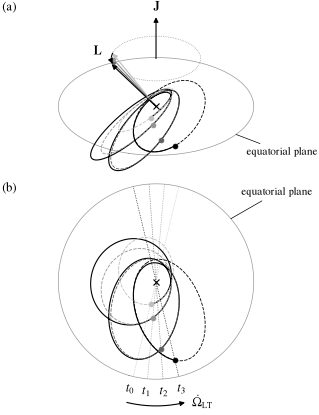

In [5]:
# Layout: both panels at the same drawing scale, placed in mm at the printed size
XLIM = (-62, 62)
YLIM_A = (min(side(circle)[:, 1].min(), side(path)[:, 1].min()) - 2, side([0, 0, J_LEN])[0, 1] + 9)
YLIM_B = (-74, 56)
HEIGHT = 1.2 * COLUMN
TOP, GAP, BOTTOM = 0.5, 2.0, 0.5    # [mm]
CENTRE = 40.0                       # black hole x [mm]: left of the middle, leaves room for the labels
spans = YLIM_A[1] - YLIM_A[0], YLIM_B[1] - YLIM_B[0]
S = (HEIGHT - TOP - GAP - BOTTOM) / sum(spans)    # mm per drawing unit
fig = plt.figure(figsize=(COLUMN * MM, HEIGHT * MM))


def panel(ylim, top_mm):
    """Axes at the shared scale S, top edge top_mm below the figure top."""
    width, height = (XLIM[1] - XLIM[0]) * S, (ylim[1] - ylim[0]) * S
    left = CENTRE + XLIM[0] * S
    ax = fig.add_axes([left / COLUMN, (HEIGHT - top_mm - height) / HEIGHT, width / COLUMN, height / HEIGHT])
    ax.set(xlim=XLIM, ylim=ylim)
    ax.set_axis_off()
    return ax


ax_a = panel(YLIM_A, TOP)
ax_b = panel(YLIM_B, TOP + spans[0] * S + GAP)

# (a) oblique view
ax_a.plot(*side(circle).T, color="0.6", lw=0.5)
label_at = np.radians(-35) - ROT    # front right of the plane rim
rim = side(R_PLANE * np.array([np.cos(label_at), np.sin(label_at), 0.0]))[0]
ax_a.annotate("equatorial plane", rim, rim + (6, -7), fontsize=ANNOTATION, ha="left", va="top", arrowprops=leader)
ax_a.plot(*side(path).T, color="k", lw=0.8, zorder=3)
for k, grey in zip(SNAPS, GREYS):
    ax_a.plot(*side(kepler(k, f)).T, color=grey, lw=0.6, ls=(0, (4, 1.5)), zorder=4)
    ax_a.plot(*side(kepler(k, -els["omega"][k]))[0], "o", ms=3.5, mfc=grey, mec=grey, mew=0.5, zorder=6)
    ax_a.annotate("", side(L_LEN * pole(k))[0], (0, 0), arrowprops=dict(arrow, lw=0.8, color=grey))
inc0 = els["inc"][SNAPS[0]]
cone = L_LEN * np.stack([np.sin(inc0) * np.cos(f), np.sin(inc0) * np.sin(f), np.cos(inc0) + 0 * f], axis=-1)
ax_a.plot(*side(cone).T, ls=(0, (1, 1.5)), color="0.55", lw=0.5)
phis = np.linspace(Omega[SNAPS[0]], Omega[SNAPS[-1]], 60) - np.pi / 2
arc = L_LEN * np.stack([np.sin(inc0) * np.cos(phis), np.sin(inc0) * np.sin(phis), np.cos(inc0) + 0 * phis], axis=-1)
ax_a.plot(*side(arc[:-1]).T, color="k", lw=0.8)
ax_a.annotate("", side(arc[-1])[0], side(arc[-4])[0], arrowprops=dict(arrow, lw=0.8, color="k"))
J_BASE = L_LEN * np.cos(inc0)    # J drawn from the centre of the L cone, clear of the orbit
ax_a.annotate("", side([0, 0, J_LEN])[0], side([0, 0, J_BASE])[0], arrowprops=dict(arrow, lw=0.8, color="k"))
ax_a.text(*side([0, 0, J_LEN])[0] + (0, 2), r"$\mathbf{J}$", ha="center", va="bottom")
ax_a.text(*side(1.3 * L_LEN * pole(SNAPS[-1]))[0], r"$\mathbf{L}$", ha="center", va="center")
ax_a.plot(0, 0, "x", ms=4, mew=0.8, color="k", zorder=7)

# (b) view from the spin axis
ax_b.plot(*top(circle).T, color="0.6", lw=0.5)
rim = R_PLANE * np.array([np.cos(np.radians(40)), np.sin(np.radians(40))])
ax_b.annotate("equatorial plane", rim, rim + (6, 12), fontsize=ANNOTATION, ha="left", va="bottom", arrowprops=leader)
ax_b.plot(*top(path).T, color="k", lw=0.8, zorder=3)
for n, (k, grey) in enumerate(zip(SNAPS, GREYS)):
    ax_b.plot(*top(kepler(k, f)).T, color=grey, lw=0.6, ls=(0, (4, 1.5)), zorder=4)
    node = top(kepler(k, -els["omega"][k]))[0]
    direction = node / np.linalg.norm(node)
    ax_b.plot(*np.stack([-R_PLANE * direction, R_PLANE * direction]).T, ls=(0, (1, 1.5)), color=grey, lw=0.5, zorder=1)
    ax_b.plot(*node, "o", ms=3.5, mfc=grey, mec=grey, mew=0.5, zorder=6)
    ax_b.text(*(R_PLANE + 7) * direction, f"$t_{n}$", ha="center", va="center")
phis = np.linspace(Omega[SNAPS[0]], Omega[SNAPS[-1]], 80)
arc = top((R_PLANE + 15) * np.stack([np.cos(phis), np.sin(phis), 0 * phis], axis=-1))
ax_b.plot(*arc[:-3].T, color="k", lw=0.8)
ax_b.annotate("", arc[-1], arc[-4], arrowprops=dict(arrow, lw=0.8, color="k"))
ax_b.text(*arc[-1] + (4, 0), r"$\dot\Omega_{\rm LT}$", ha="left", va="center")
ax_b.plot(0, 0, "x", ms=4, mew=0.8, color="k", zorder=7)

for ax, name in ((ax_a, "(a)"), (ax_b, "(b)")):
    fig.text(0.01, ax.get_position().y1, name, va="top")

save_paper_figure(fig, "lense-thirring", "lense-thirring-orbit")
plt.show()

Check against the A&A rules (schematic: height up to $1.2\times$ the width):

In [6]:
pd.DataFrame([aanda_check(fig, max_height=1.2 * COLUMN)])

,width_mm,height_mm,fonts_pt,lines_pt
0,88.0,105.6,"[7.5, 9.0]","[0.5, 0.6, 0.8, 1.0]"


## 2. ISCO, prograde and retrograde

Equatorial radii of a Kerr black hole with $\chi=0.5$, read from Relatipy (`horizons.event`, `r_isco_prograde`, `r_isco_retrograde`), and the $\chi=0$ ISCO as reference. No orbit is integrated.

In [7]:
CHI = 0.5
ANNOTATION = 7.5    # [pt]
bh = rp.Kerr(mass=4.3e6 * u.Msun, spin=CHI)
radius = {
    name: (value / bh.r_g).to_value(u.one)
    for name, value in (
        ("horizon", bh.horizons.event),
        ("prograde", bh.r_isco_prograde),
        ("retrograde", bh.r_isco_retrograde),
        ("schwarzschild", rp.Kerr(mass=4.3e6 * u.Msun, spin=0.0).r_isco_prograde),
    )
}
pd.Series(radius, name="r [M]")

horizon          1.866025
prograde         4.233003
retrograde       7.554585
schwarzschild    6.000000
Name: r [M], dtype: float64

Figure: view from the spin axis, drawn as the face-on views of `relatipy.plotting` but in black and white; the black hole turns counter-clockwise.

* thin solid circle: event horizon, named inside with its radius in $M$; the solid arc with a filled arrowhead just outside it gives the sense of rotation of the black hole
* long dashes: prograde and retrograde ISCO; open chevrons give the sense of the orbit (four per circle, as `relatipy.plotting`)
* fine dotted grey: ISCO for $\chi=0$ ($6M$), no sense
* each ISCO is named on its own line (prograde and $\chi=0$ on top, retrograde at the bottom); these labels are drawn as paths bent along the circle, at 7.5 pt

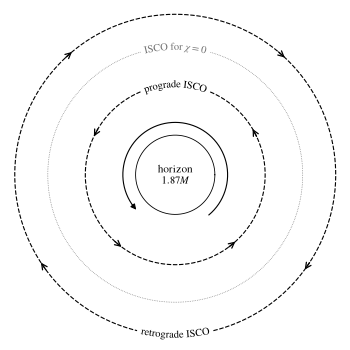

In [8]:
# Layout: view from the spin axis, as the face-on views of relatipy.plotting, in black and white;
# each ISCO carries its label on the line (prograde and chi = 0 on top, retrograde at the bottom), the horizon inside
LIM = radius["retrograde"] + 0.6    # half width of the drawing [M]
SIDE = 0.75 * COLUMN                # drawing side [mm], centred in the column width
S = SIDE / (2 * LIM)                # mm per M
fig = plt.figure(figsize=(COLUMN * MM, SIDE * MM))
ax = fig.add_axes([(1 - SIDE / COLUMN) / 2, 0, SIDE / COLUMN, 1])
ax.set(xlim=(-LIM, LIM), ylim=(-LIM, LIM), aspect="equal")
ax.set_axis_off()

PAD = 0.2           # free arc on each side of a label [M]
CHEVRONS = 4        # per ISCO, as relatipy.plotting
phi = np.linspace(0, 2 * np.pi, 600)
chevron = dict(arrowstyle="->", lw=0.9, color="k", shrinkA=0, shrinkB=0, mutation_scale=10)


def labelled_circle(r, text, top, color="k", **line):
    """Circle of radius r [M] with its label bent along the line, upright, in a gap at the top or bottom.

    Returns the free arc (start, length) [rad], counter-clockwise from the end of the label.
    """
    path = TextPath((0, 0), text, size=ANNOTATION, prop=FontProperties(family="serif"))
    box = path.get_extents()
    xy = (path.vertices - [box.intervalx.mean(), box.intervaly.mean()]) * 25.4 / 72 / S    # pt to M, centred
    centre, sense = (np.pi / 2, -1) if top else (3 * np.pi / 2, +1)    # left to right on the page
    theta = centre + sense * xy[:, 0] / r
    rho = r - sense * xy[:, 1]
    bent = mpath.Path(np.stack([rho * np.cos(theta), rho * np.sin(theta)], axis=-1), path.codes)
    ax.add_patch(PathPatch(bent, fc=color, ec="none", lw=0))
    half = (box.width / 2 * 25.4 / 72 / S + PAD) / r
    phi = np.linspace(centre + half, centre + 2 * np.pi - half, 600)
    ax.plot(r * np.cos(phi), r * np.sin(phi), color=color, **line)
    return centre + half, 2 * np.pi - 2 * half


def chevrons(r, free, sense):
    """CHEVRONS open arrowheads spread along the free arc; sense +1 counter-clockwise (as the spin), -1 clockwise."""
    start, length = free
    for phi in start + length * (np.arange(CHEVRONS) + 0.5) / CHEVRONS:
        step = sense * 0.2 / r    # short chord along the circle [rad]
        ax.annotate("", r * np.array([np.cos(phi + step), np.sin(phi + step)]),
                    r * np.array([np.cos(phi - step), np.sin(phi - step)]), arrowprops=chevron)


ax.plot(*(radius["horizon"] * np.stack([np.cos(phi), np.sin(phi)])), color="k", lw=0.6)
ax.text(0, 0, f"horizon\n${radius['horizon']:.2f}M$", fontsize=ANNOTATION, ha="center", va="center", linespacing=1.2)
R_SPIN = radius["horizon"] + 0.6    # sense of rotation of the black hole, just outside the horizon [M]
spin = np.radians(np.linspace(-50, 215, 200))
ax.plot(R_SPIN * np.cos(spin), R_SPIN * np.sin(spin), color="k", lw=0.8)
ax.annotate("", R_SPIN * np.array([np.cos(spin[-1] + 0.12), np.sin(spin[-1] + 0.12)]),
            R_SPIN * np.array([np.cos(spin[-1]), np.sin(spin[-1])]),
            arrowprops=dict(arrowstyle="-|>", lw=0.8, color="k", shrinkA=0, shrinkB=0, mutation_scale=8))
labelled_circle(radius["schwarzschild"], r"ISCO for $\chi=0$", top=True, color="0.45", lw=0.5, ls=(0, (1, 1.5)))
free = labelled_circle(radius["prograde"], "prograde ISCO", top=True, lw=0.8, ls=(0, (4, 1.5)))
chevrons(radius["prograde"], free, +1)
free = labelled_circle(radius["retrograde"], "retrograde ISCO", top=False, lw=0.8, ls=(0, (4, 1.5)))
chevrons(radius["retrograde"], free, -1)

save_paper_figure(fig, "isco", "isco-diagram")
plt.show()

Check against the A&A rules (schematic: height up to $1.2\times$ the width):

In [9]:
pd.DataFrame([aanda_check(fig, max_height=1.2 * COLUMN)])

,width_mm,height_mm,fonts_pt,lines_pt
0,88.0,88.0,[7.5],"[0.5, 0.6, 0.8, 1.0]"


## 3. Pericentre precession

Equatorial prograde orbit around a Kerr black hole with $\chi=0.99$, spin along $z$, started at apocentre ($f=180^\circ$) from Keplerian elements:

* semi-major axis $a=111.1M$ (semi-latus rectum $p=40M$), eccentricity $e=0.8$, inclination $i=0$; $p$ sets the advance to about $26^\circ$ per orbit, $e$ makes the loops long and thin so that they cross little
* DOP853, `rtol=1e-12`, `atol=1e-14`, five Keplerian periods with 20000 samples per period (smooth path near pericentre)
* positions in the spin frame with `spin_frame_positions` (section 1)

How the orbit is read:

* pericentres: samples where $r$ is a local minimum; the pericentre is the vertex of the parabola through that sample and its two neighbours, and $\phi$ is read from the parabola through the same three samples
* $\psi$: azimuth of each pericentre with the whole turns removed; $\Delta\phi$ is its change in one orbit
* at each pericentre, a reference Keplerian ellipse (not drawn; it places the apocentre dots) (focus at the black hole) with the pericentre $r_p$ and apocentre $r_a$ of the integrated orbit, its major axis along that pericentre. It touches the path at the pericentre; it is a drawing aid, not an osculating orbit: in this strong field the Newtonian osculating ellipse taken at pericentre misses the apocentre badly

In [10]:
PP = dict(chi=0.99, p=40.0, e=0.8, n_periods=5)
a0 = PP["p"] / (1 - PP["e"]**2)
t = np.linspace(0, PP["n_periods"] * 2 * np.pi * a0**1.5, 20000 * PP["n_periods"] + 1)
x = spin_frame_positions(initial_state(a0, PP["e"], 0.0, 0.0), t, PP["chi"])[:, :2]
r = np.linalg.norm(x, axis=1)
phi = np.unwrap(np.arctan2(x[:, 1], x[:, 0]))

k = np.where((r[1:-1] < r[:-2]) & (r[1:-1] <= r[2:]))[0] + 1           # sample closest to each pericentre
s = 0.5 * (r[k - 1] - r[k + 1]) / (r[k - 1] - 2 * r[k] + r[k + 1])    # parabola vertex [steps from sample k]
peri = dict(
    t=t[k] + s * (t[1] - t[0]),
    r=r[k] - 0.25 * (r[k - 1] - r[k + 1]) * s,
    phi=phi[k] + 0.5 * (phi[k + 1] - phi[k - 1]) * s + 0.5 * (phi[k + 1] - 2 * phi[k] + phi[k - 1]) * s**2,
)
psi = peri["phi"] - 2 * np.pi * np.arange(len(k))    # pericentre azimuths, whole turns removed
r_apo = r.max()

pd.DataFrame(dict(
    t_M=peri["t"],
    r_p_M=peri["r"],
    r_a_M=r_apo,
    psi_deg=np.degrees(psi),
    dphi_deg=np.r_[np.nan, np.degrees(np.diff(psi))],
), index=pd.Index(range(len(k)), name="pericentre"))

,t_M,r_p_M,r_a_M,psi_deg,dphi_deg
pericentre,,,,,
0,3732.672749,20.725689,200.0,372.783385,NaN
1,11198.018246,20.725689,200.0,398.350153,25.566769
2,18663.363743,20.725689,200.0,423.916922,25.566768
3,26128.709240,20.725689,200.0,449.483690,25.566768
4,33594.054737,20.725689,200.0,475.050459,25.566768


Figure: view from the spin axis; the orbit and the black hole turn counter-clockwise. The first four pericentres, $t_0$ to $t_3$ (three orbits), toward the bottom as the nodes in section 1.

* solid grey: integrated path from $t_0$ to $t_3$, light so that the pericentres stand out on it
* black dots on the path: pericentres $t_0$ to $t_3$
* grey dots: antipode of each pericentre, at $r_a$ on its line of apsides (apocentre of the reference ellipse), grey from light ($t_0$) to black ($t_3$); named from outside the orbit
* dotted: line of apsides of each pericentre, same greys, through the black hole to just outside the drawing on both sides; $t_n$ is written in a row below the pericentres, as the nodes in section 1
* arrows: advance $\Delta\phi$ of the line of apsides in one orbit, from $t_1$ to $t_2$, the same at both ends

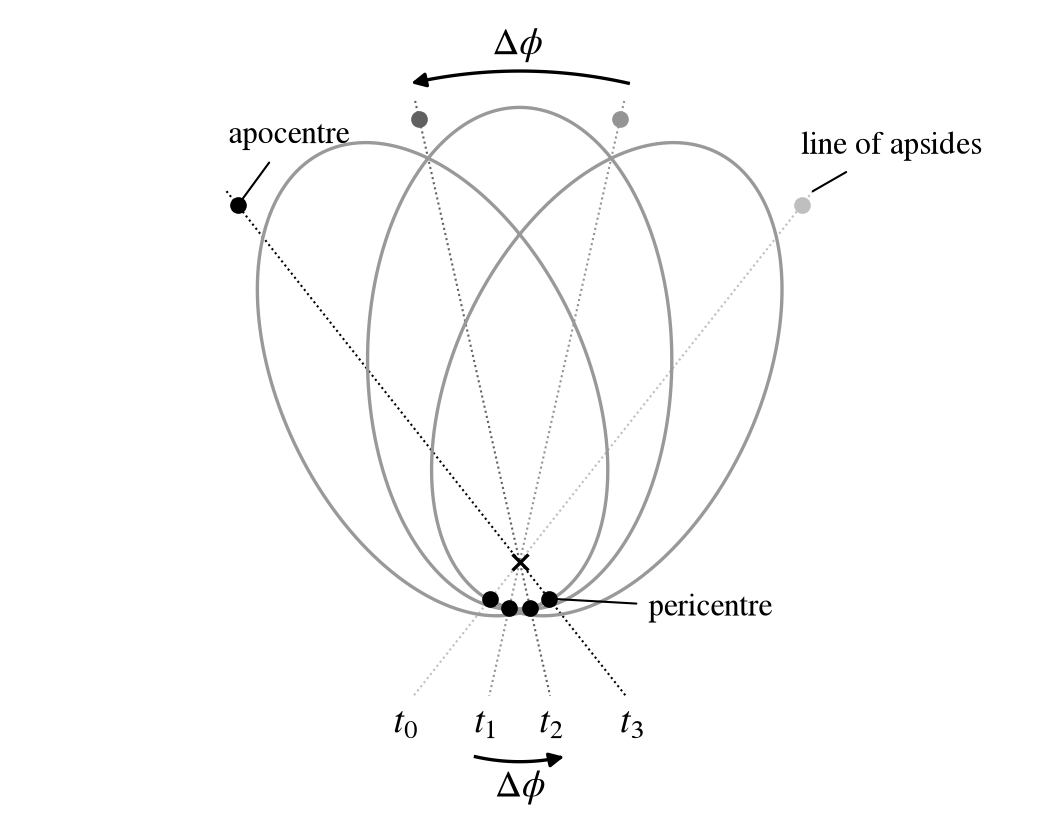

In [11]:
# Layout: view from the spin axis, same scale on both axes; height fitted to the drawing
APSES = [0, 1, 2, 3]    # pericentres drawn
RA, RP = r_apo, peri["r"].mean()
TURN = np.radians(-90) - (psi[APSES[0]] + psi[APSES[-1]]) / 2    # screen azimuth: pericentres toward the bottom


def face_on(p):
    """View from +z, rotated by TURN."""
    p = np.atleast_2d(p)
    c, s = np.cos(TURN), np.sin(TURN)
    return np.stack([c * p[:, 0] - s * p[:, 1], s * p[:, 0] + c * p[:, 1]], axis=-1)


def unit(angle):
    """Unit vector toward azimuth angle, on the page."""
    return face_on([np.cos(angle), np.sin(angle)])[0]


def ellipse(j, f):
    """Reference ellipse of pericentre j at true anomaly f, on the page [M]."""
    a, e = (RP + RA) / 2, (RA - RP) / (RA + RP)
    rr = a * (1 - e**2) / (1 + e * np.cos(f))
    return face_on(np.stack([rr * np.cos(psi[j] + f), rr * np.sin(psi[j] + f)], axis=-1))


f = np.linspace(0, 2 * np.pi, 1200)
path = face_on(x[k[APSES[0]] - 1:k[APSES[-1]] + 2])
curves = np.concatenate([path, *[ellipse(j, f) for j in APSES]])
polar = np.arctan2(curves[:, 1], curves[:, 0])


def reach(direction, width=np.radians(4)):
    """Farthest curve point within width of a page direction [M]."""
    near = np.abs(np.angle(np.exp(1j * (polar - np.arctan2(direction[1], direction[0]))))) < width
    return np.linalg.norm(curves[near], axis=1).max()


R_PERI = [reach(unit(psi[j])) + 0.04 * RA for j in APSES]     # lines of apsides stop just outside the curves
R_APO = [reach(-unit(psi[j])) + 0.04 * RA for j in APSES]
SIDE = 0.65 * COLUMN                                          # drawing width [mm], centred in the column width
LABEL_GAP = 5.5                                               # between the t1 and t2 labels [mm]

# t_n labels in a row below the pericentres, as the nodes in section 1, far enough down to keep them apart
to_mm = SIDE / (np.ptp(curves[:, 0]) + 0.08 * RA)          # approximate scale [mm per M]
slope = [unit(psi[j])[0] / -unit(psi[j])[1] for j in APSES]    # x per unit depth below the black hole
depth = max(LABEL_GAP / to_mm / (slope[2] - slope[1]), max(R_PERI) + 0.02 * RA)
labels = [np.array([depth * slope[n], -depth]) for n in range(len(APSES))]
phis = np.linspace(psi[APSES[1]], psi[APSES[2]], 60)                                       # advance from t1 to t2
arc_a = np.array([(max(R_APO[1:3]) + 0.04 * RA) * unit(angle + np.pi) for angle in phis])    # beyond the apocentres
arc_p = np.array([(depth / -unit(psi[APSES[1]])[1] + 4.5 / to_mm) * unit(angle) for angle in phis])    # below the labels
far = ellipse(APSES[-1], np.array([np.pi]))[0]
far_label = far + (-0.02 * RA, 0.12 * RA)    # apocentre named from outside the orbit
end = -R_APO[0] * unit(psi[APSES[0]])
end_label = end + (-1.0 / to_mm, 2.5 / to_mm)    # line of apsides named above its end, clear of the orbit
box = np.concatenate([
    curves, labels, arc_a, arc_p, [arc_a[30] + (0, 4.5 / to_mm), arc_p[30] - (0, 4.5 / to_mm), far_label + (0, 3 / to_mm), end_label + (0, 3 / to_mm)],
    *[[-R_APO[n] * unit(psi[j])] for n, j in enumerate(APSES)],
])
pad = 0.04 * RA
XLIM = (box[:, 0].min() - pad, box[:, 0].max() + pad)
YLIM = (box[:, 1].min() - pad, box[:, 1].max() + pad)
HEIGHT = SIDE * (YLIM[1] - YLIM[0]) / (XLIM[1] - XLIM[0])
fig = plt.figure(figsize=(COLUMN * MM, HEIGHT * MM))
ax = fig.add_axes([(1 - SIDE / COLUMN) / 2, 0, SIDE / COLUMN, 1])
ax.set(xlim=XLIM, ylim=YLIM)
ax.set_axis_off()

ax.plot(*path.T, color="0.6", lw=0.8, zorder=3)    # light, so that the pericentres stand out
for n, (j, grey) in enumerate(zip(APSES, GREYS)):
    direction = unit(psi[j])    # toward the pericentre
    reach_p = (depth - 0.02 * RA) / -direction[1]    # down to just above the labels
    ax.plot(*np.stack([-R_APO[n] * direction, reach_p * direction]).T, ls=(0, (1, 1.5)), color=grey, lw=0.5, zorder=1)
    ax.plot(*peri["r"][j] * direction, "o", ms=3.5, mfc="k", mec="k", mew=0.5, zorder=6)
    ax.plot(*ellipse(j, np.array([np.pi]))[0], "o", ms=3.5, mfc=grey, mec=grey, mew=0.5, zorder=6)
    ax.text(*labels[n], f"$t_{n}$", ha="center", va="top")
ax.annotate("line of apsides", end, end_label, fontsize=ANNOTATION, ha="left", va="bottom", arrowprops=leader)
ax.annotate("apocentre", far, far_label, fontsize=ANNOTATION, ha="left", va="bottom", arrowprops=leader)
last = peri["r"][APSES[-1]] * unit(psi[APSES[-1]])
ax.annotate("pericentre", last, last + (0.22 * RA, -0.02 * RA), fontsize=ANNOTATION, ha="left", va="center", arrowprops=leader)
for arc, side in ((arc_a, +1), (arc_p, -1)):
    ax.plot(*arc[:-3].T, color="k", lw=0.8)
    ax.annotate("", arc[-1], arc[-4], arrowprops=dict(arrow, lw=0.8, color="k"))
    ax.text(*arc[30] + (0, side * 0.6 / to_mm), r"$\Delta\phi$", ha="center", va="bottom" if side > 0 else "top")
ax.plot(0, 0, "x", ms=4, mew=0.8, color="k", zorder=7)

save_paper_figure(fig, "precession", "precession-orbit")
plt.show()

Check against the A&A rules (schematic: height up to $1.2\times$ the width):

In [12]:
pd.DataFrame([aanda_check(fig, max_height=1.2 * COLUMN)])

,width_mm,height_mm,fonts_pt,lines_pt
0,88.0,94.2,"[7.5, 9.0]","[0.5, 0.6, 0.8, 1.0]"
